In [5]:
!pip uninstall -y google-generativeai

Found existing installation: google-generativeai 0.8.6
Uninstalling google-generativeai-0.8.6:
  Successfully uninstalled google-generativeai-0.8.6


In [6]:
!pip install -q google-genai

In [7]:
!pip install -q "protobuf==6.33.5"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-status 1.71.2 requires protobuf<6.0dev,>=5.26.1, but you have protobuf 6.33.5 which is incompatible.
google-ai-generativelanguage 0.6.15 requires protobuf!=4.21.0,!=4.21.1,!=4.21.2,!=4.21.3,!=4.21.4,!=4.21.5,<6.0.0dev,>=3.20.2, but you have protobuf 6.33.5 which is incompatible.


In [8]:
!pip uninstall -y grpcio-status google-ai-generativelanguage

Found existing installation: grpcio-status 1.71.2
Uninstalling grpcio-status-1.71.2:
  Successfully uninstalled grpcio-status-1.71.2
Found existing installation: google-ai-generativelanguage 0.6.15
Uninstalling google-ai-generativelanguage-0.6.15:
  Successfully uninstalled google-ai-generativelanguage-0.6.15


In [9]:
import google.protobuf

print("Protobuf version:", google.protobuf.__version__)

Protobuf version: 6.33.5


In [1]:
import torch
import gradio
import transformers
import diffusers
import google.protobuf

print("PyTorch:", torch.__version__)
print("Gradio:", gradio.__version__)
print("Transformers:", transformers.__version__)
print("Diffusers:", diffusers.__version__)
print("Protobuf:", google.protobuf.__version__)

print("GPU Available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))

print("\nAll checks completed!")

PyTorch: 2.14.1+cu130
Gradio: 6.31.0
Transformers: 5.22.1
Diffusers: 0.42.1
Protobuf: 6.33.5
GPU Available: True
GPU Name: Tesla T4

All checks completed!


In [2]:
!git clone https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix.git

Cloning into 'pytorch-CycleGAN-and-pix2pix'...
remote: Enumerating objects: 2619, done.
remote: Total 2619 (delta 0), reused 0 (delta 0), pack-reused 2619 (from 1)
Receiving objects: 100% (2619/2619), 8.24 MiB | 34.01 MiB/s, done.
Resolving deltas: 100% (1654/1654), done.


In [3]:
%cd /content/pytorch-CycleGAN-and-pix2pix

/content/pytorch-CycleGAN-and-pix2pix


In [5]:
!pip install -q dominate visdom wandb

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [7]:
import torch
import dominate
import visdom

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("CycleGAN dependencies installed successfully!")

PyTorch: 2.14.1+cu130
CUDA available: True
CycleGAN dependencies installed successfully!


In [8]:
!bash ./scripts/download_cyclegan_model.sh horse2zebra

Note: available models are apple2orange, orange2apple, summer2winter_yosemite, winter2summer_yosemite, horse2zebra, zebra2horse, monet2photo, style_monet, style_cezanne, style_ukiyoe, style_vangogh, sat2map, map2sat, cityscapes_photo2label, cityscapes_label2photo, facades_photo2label, facades_label2photo, iphone2dslr_flower
Specified [horse2zebra]
for details.

--2026-11-07 07:11:38--  http://efrosgans.eecs.berkeley.edu/cyclegan/pretrained_models/horse2zebra.pth
Resolving efrosgans.eecs.berkeley.edu (efrosgans.eecs.berkeley.edu)... 128.32.139.28
Connecting to efrosgans.eecs.berkeley.edu (efrosgans.eecs.berkeley.edu)|128.32.139.28|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 45575747 (43M)
Saving to: ‘./checkpoints/horse2zebra_pretrained/latest_net_G.pth’

./checkpoints/horse 100%[===================>]  43.46M  52.5MB/s    in 0.8s    

2026-11-07 07:11:39 (52.5 MB/s) - ‘./checkpoints/horse2zebra_pretrained/latest_net_G.pth’ saved [45575747/45575747]



In [9]:
import os

model_path = "./checkpoints/horse2zebra_pretrained/latest_net_G.pth"

if os.path.exists(model_path):
    print("Horse-to-Zebra model downloaded successfully!")
    print("Model size:", round(os.path.getsize(model_path) / (1024 * 1024), 2), "MB")
else:
    print("Model file not found. We need to check the download.")

Horse-to-Zebra model downloaded successfully!
Model size: 43.46 MB


In [10]:
from google.colab import files

uploaded = files.upload()

Saving beautiful-chestnut-horse-standing-in-perfect-exterior.webp to beautiful-chestnut-horse-standing-in-perfect-exterior.webp


Original image: beautiful-chestnut-horse-standing-in-perfect-exterior.webp
Generating zebra image...
Original Horse:


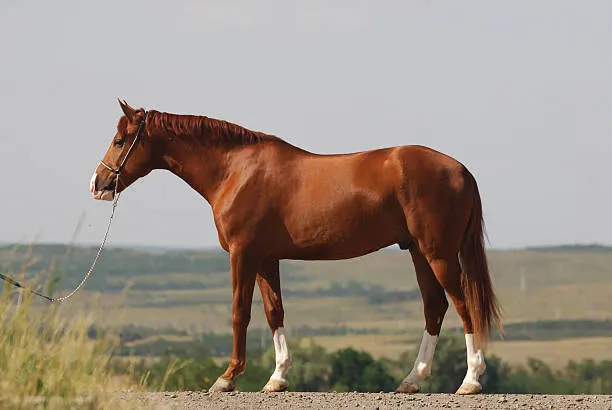

Generated Zebra:


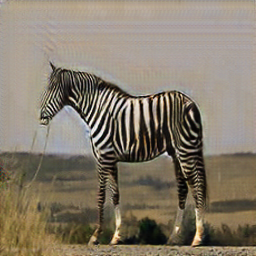

SUCCESS! Image transformation completed.


In [11]:
import os
import subprocess
from PIL import Image
from IPython.display import display

# Get uploaded image
image_name = list(uploaded.keys())[0]

print("Original image:", image_name)

# Open image
original_image = Image.open(image_name).convert("RGB")

# Save image in temporary input folder
os.makedirs("/content/horse_input", exist_ok=True)

original_image.save("/content/horse_input/horse.jpg")

# Run pretrained CycleGAN
command = [
    "python", "test.py",
    "--dataroot", "/content/horse_input",
    "--name", "horse2zebra_pretrained",
    "--model", "test",
    "--dataset_mode", "single",
    "--direction", "AtoB",
    "--no_dropout",
    "--num_test", "1"
]

print("Generating zebra image...")

subprocess.run(command, check=True)

# Load generated image
output_path = (
    "/content/pytorch-CycleGAN-and-pix2pix/"
    "results/horse2zebra_pretrained/test_latest/images/horse_fake.png"
)

# Display original and generated images
if os.path.exists(output_path):

    print("Original Horse:")
    display(original_image)

    print("Generated Zebra:")
    display(Image.open(output_path))

    print("SUCCESS! Image transformation completed.")

else:
    print("Generated image not found. Please share the error.")

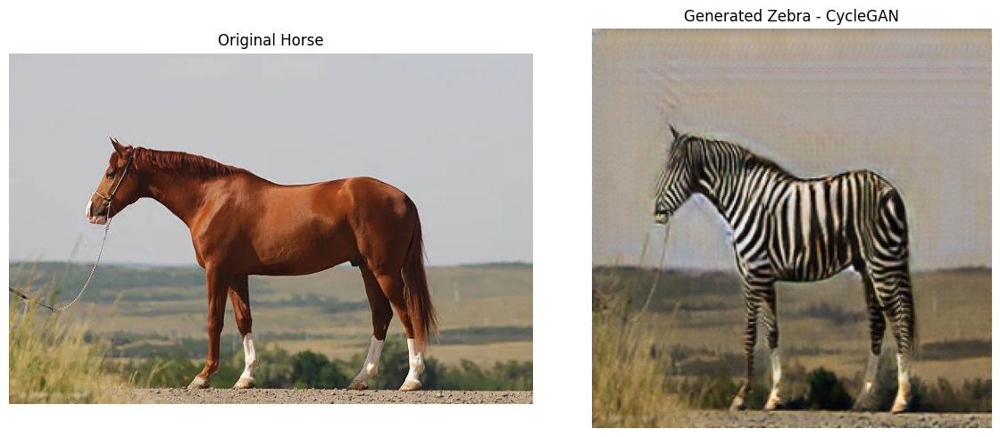

In [12]:
import matplotlib.pyplot as plt

generated_image = Image.open(output_path).convert("RGB")

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Horse")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(generated_image)
plt.title("Generated Zebra - CycleGAN")
plt.axis("off")

plt.tight_layout()
plt.show()

# **Zebra to Horse model**

In [13]:
print("Horse-to-Zebra model supports both directions!")
print("AtoB = Horse to Zebra")
print("BtoA = Zebra to Horse")

Horse-to-Zebra model supports both directions!
AtoB = Horse to Zebra
BtoA = Zebra to Horse


In [14]:
from google.colab import files

zebra_uploaded = files.upload()

Saving zebra-in-open-landscape.webp to zebra-in-open-landscape.webp


In [17]:
!bash ./scripts/download_cyclegan_model.sh monet2photo


Note: available models are apple2orange, orange2apple, summer2winter_yosemite, winter2summer_yosemite, horse2zebra, zebra2horse, monet2photo, style_monet, style_cezanne, style_ukiyoe, style_vangogh, sat2map, map2sat, cityscapes_photo2label, cityscapes_label2photo, facades_photo2label, facades_label2photo, iphone2dslr_flower
Specified [monet2photo]
for details.

--2026-11-07 07:20:19--  http://efrosgans.eecs.berkeley.edu/cyclegan/pretrained_models/monet2photo.pth
Resolving efrosgans.eecs.berkeley.edu (efrosgans.eecs.berkeley.edu)... 128.32.139.28
Connecting to efrosgans.eecs.berkeley.edu (efrosgans.eecs.berkeley.edu)|128.32.139.28|:80... connected.
HTTP request sent, awaiting response... 200 OK
Length: 45575747 (43M)
Saving to: ‘./checkpoints/monet2photo_pretrained/latest_net_G.pth’

./checkpoints/monet 100%[===================>]  43.46M  52.8MB/s    in 0.8s    

2026-11-07 07:20:20 (52.8 MB/s) - ‘./checkpoints/monet2photo_pretrained/latest_net_G.pth’ saved [45575747/45575747]



Generating Horse from Zebra...
Original Zebra:


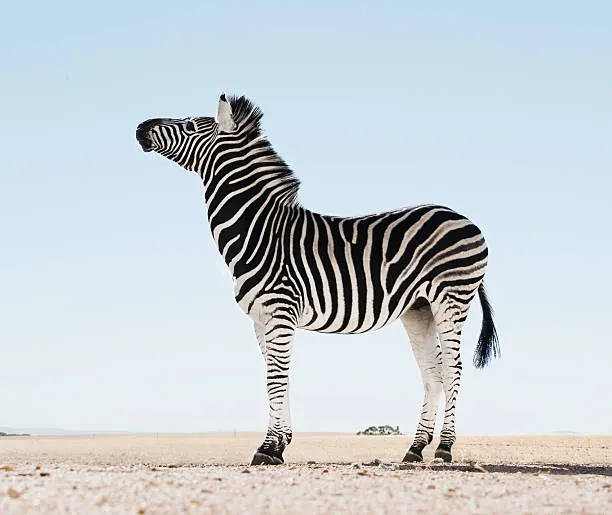

Generated Horse:


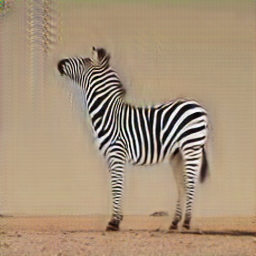

Zebra-to-Horse completed!


In [16]:
import os
import subprocess
import glob
from PIL import Image
from IPython.display import display

# Create a separate output folder
output_folder = "/content/zebra_to_horse_results"

# Remove old output if it exists
import shutil
if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

# Run CycleGAN
command = [
    "python", "test.py",
    "--dataroot", "/content/zebra_input",
    "--name", "horse2zebra_pretrained",
    "--model", "test",
    "--dataset_mode", "single",
    "--direction", "BtoA",
    "--no_dropout",
    "--num_test", "1",
    "--results_dir", output_folder
]

print("Generating Horse from Zebra...")

subprocess.run(command, check=True)

# Find the new generated image
results = glob.glob(
    output_folder + "/horse2zebra_pretrained/test_latest/images/*_fake.png"
)

if results:
    horse_output = Image.open(results[0]).convert("RGB")

    print("Original Zebra:")
    display(zebra_image)

    print("Generated Horse:")
    display(horse_output)

    print("Zebra-to-Horse completed!")
else:
    print("No generated image found.")

# Monet-to-Photo model

In [18]:
import os

model_folder = "./checkpoints/monet2photo_pretrained"

if os.path.exists(model_folder):
    print("Monet model downloaded successfully!")
    print("Model files:")

    for file in os.listdir(model_folder):
        print(file)
else:
    print("Model folder not found. Please check the download.")

Monet model downloaded successfully!
Model files:
latest_net_G.pth


In [19]:
from google.colab import files

photo_uploaded = files.upload()

Saving Screenshot 2026-11-07 125223.png to Screenshot 2026-11-07 125223.png


Converting photograph into Monet painting...
Original Photograph:


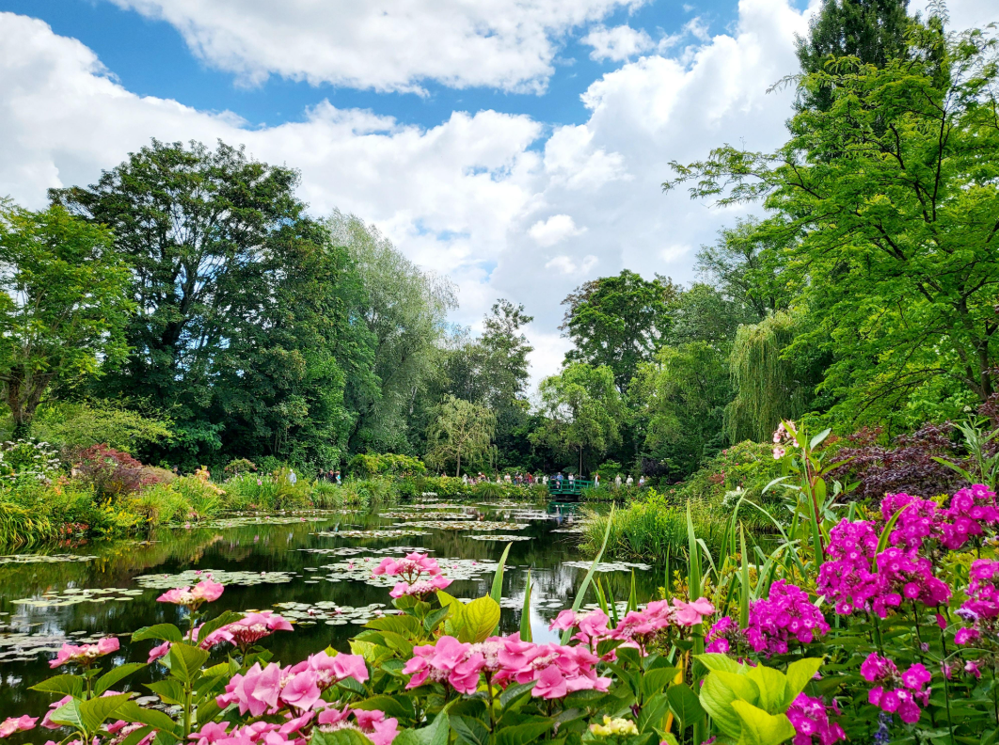

Generated Monet Painting:


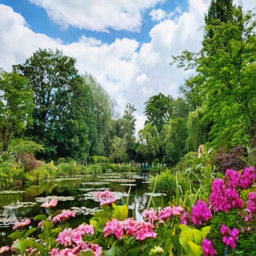

SUCCESS! Photo-to-Painting completed!


In [20]:
import os
import glob
import shutil
import subprocess
from PIL import Image
from IPython.display import display

# Get uploaded photograph
photo_name = list(photo_uploaded.keys())[0]

# Load original photograph
original_photo = Image.open(photo_name).convert("RGB")

# Save input image
os.makedirs("/content/photo_input", exist_ok=True)
original_photo.save("/content/photo_input/photo.jpg")

# Use a separate results folder
output_folder = "/content/monet_results"

if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

# CycleGAN command
command = [
    "python", "test.py",
    "--dataroot", "/content/photo_input",
    "--name", "monet2photo_pretrained",
    "--model", "test",
    "--dataset_mode", "single",
    "--direction", "BtoA",
    "--no_dropout",
    "--num_test", "1",
    "--results_dir", output_folder
]

print("Converting photograph into Monet painting...")

subprocess.run(command, check=True)

# Find generated painting
results = glob.glob(
    output_folder +
    "/monet2photo_pretrained/test_latest/images/*_fake.png"
)

if results:
    painting = Image.open(results[0]).convert("RGB")

    print("Original Photograph:")
    display(original_photo)

    print("Generated Monet Painting:")
    display(painting)

    print("SUCCESS! Photo-to-Painting completed!")

else:
    print("Generated painting not found.")

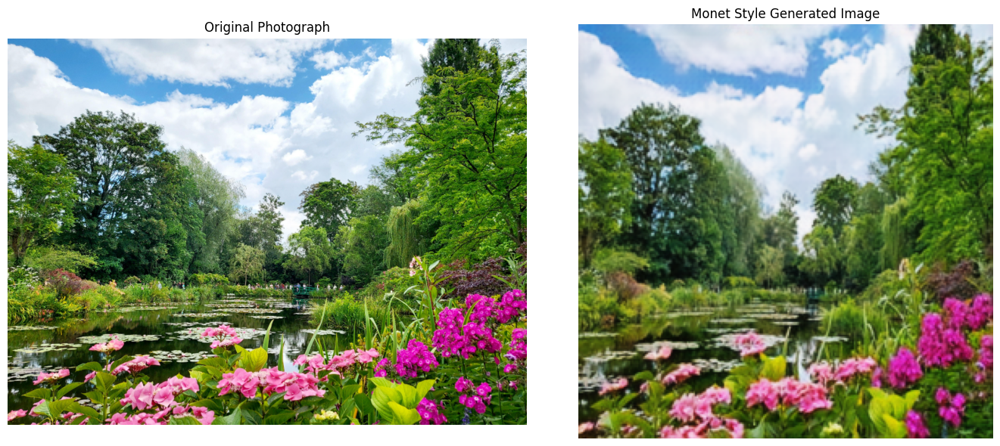

Original size: (1062, 792)
Generated size: (256, 256)


In [21]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(original_photo)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(painting)
plt.title("Monet Style Generated Image")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Original size:", original_photo.size)
print("Generated size:", painting.size)

# Painting to Photograph

Converting Monet painting into photograph...
Original Monet Painting:


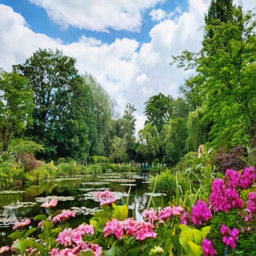

Generated Photograph:


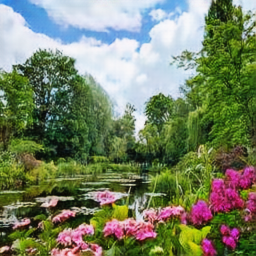

Painting-to-Photo completed!


In [22]:
import os
import glob
import shutil
import subprocess
from PIL import Image
from IPython.display import display

# Save generated painting as input
os.makedirs("/content/painting_input", exist_ok=True)

painting.save("/content/painting_input/painting.jpg")

# Create separate output folder
output_folder = "/content/painting_to_photo_results"

if os.path.exists(output_folder):
    shutil.rmtree(output_folder)

# Run CycleGAN in reverse direction
command = [
    "python", "test.py",
    "--dataroot", "/content/painting_input",
    "--name", "monet2photo_pretrained",
    "--model", "test",
    "--dataset_mode", "single",
    "--direction", "AtoB",
    "--no_dropout",
    "--num_test", "1",
    "--results_dir", output_folder
]

print("Converting Monet painting into photograph...")

subprocess.run(command, check=True)

# Find generated photograph
results = glob.glob(
    output_folder +
    "/monet2photo_pretrained/test_latest/images/*_fake.png"
)

if results:
    photo_result = Image.open(results[0]).convert("RGB")

    print("Original Monet Painting:")
    display(painting)

    print("Generated Photograph:")
    display(photo_result)

    print("Painting-to-Photo completed!")

else:
    print("Generated photograph not found.")

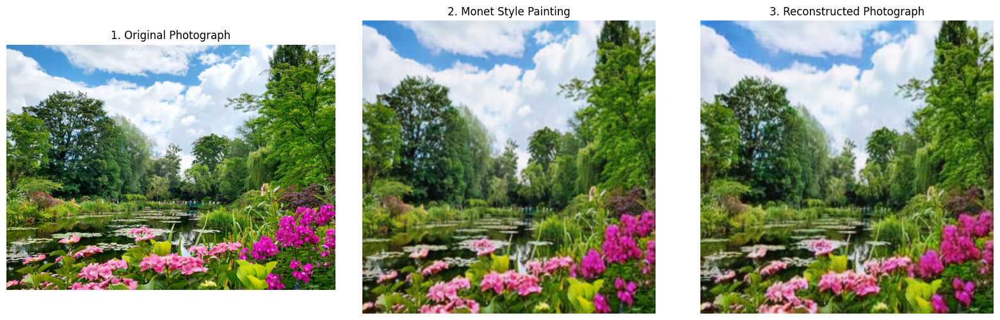

In [23]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_photo)
plt.title("1. Original Photograph")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(painting)
plt.title("2. Monet Style Painting")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(photo_result)
plt.title("3. Reconstructed Photograph")
plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
!pip install -q diffusers transformers accelerate safetensors

In [25]:
import torch
from diffusers import AutoPipelineForImage2Image

model_id = "stabilityai/sd-turbo"

pipe = AutoPipelineForImage2Image.from_pretrained(
    model_id,
    torch_dtype=torch.float16
)

pipe = pipe.to("cuda")

print("Stable Diffusion Turbo loaded successfully!")

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 12 files:   0%|          | 0/12 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

You have disabled the safety checker for <class 'diffusers.pipelines.stable_diffusion.pipeline_stable_diffusion_img2img.StableDiffusionImg2ImgPipeline'> by passing `safety_checker=None`. Ensure that you abide to the conditions of the Stable Diffusion license and do not expose unfiltered results in services or applications open to the public. Both the diffusers team and Hugging Face strongly recommend to keep the safety filter enabled in all public facing circumstances, disabling it only for use-cases that involve analyzing network behavior or auditing its results. For more information, please have a look at https://github.com/huggingface/diffusers/pull/254 .


Stable Diffusion Turbo loaded successfully!


In [26]:
import torch
from PIL import Image
from IPython.display import display

# Prepare original image
diffusion_input = original_photo.convert("RGB")
diffusion_input = diffusion_input.resize((512, 512))

print("Generating image using Stable Diffusion...")

# Generate image
with torch.inference_mode():
    diffusion_result = pipe(
        prompt="A beautiful Monet impressionist oil painting of a garden pond, colorful flowers, soft brush strokes",
        image=diffusion_input,
        strength=0.5,
        guidance_scale=0.0,
        num_inference_steps=4
    ).images[0]

print("Original Photograph:")
display(original_photo)

print("Stable Diffusion Generated Image:")
display(diffusion_result)

print("SUCCESS! Diffusion generation completed.")

SUCCESS! Diffusion generation completed.


Generating Diffusion image again...


  0%|          | 0/2 [00:00<?, ?it/s]

Diffusion image generated successfully!


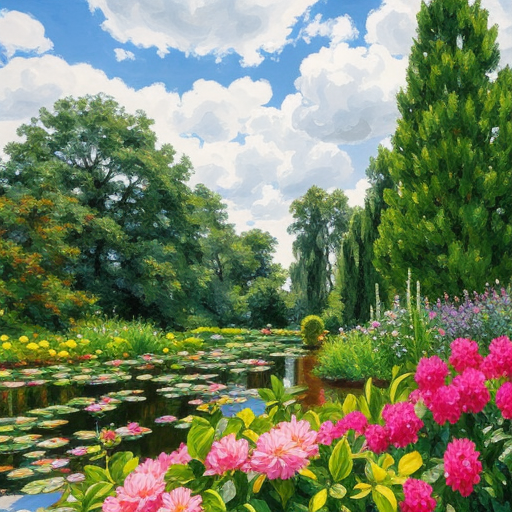

In [28]:
import torch
from IPython.display import display

print("Generating Diffusion image again...")

diffusion_result = pipe(
    prompt="A beautiful Monet impressionist oil painting of a garden pond, colorful flowers, soft brush strokes",
    image=original_photo.convert("RGB").resize((512, 512)),
    strength=0.5,
    guidance_scale=0.0,
    num_inference_steps=4
).images[0]

print("Diffusion image generated successfully!")

display(diffusion_result)

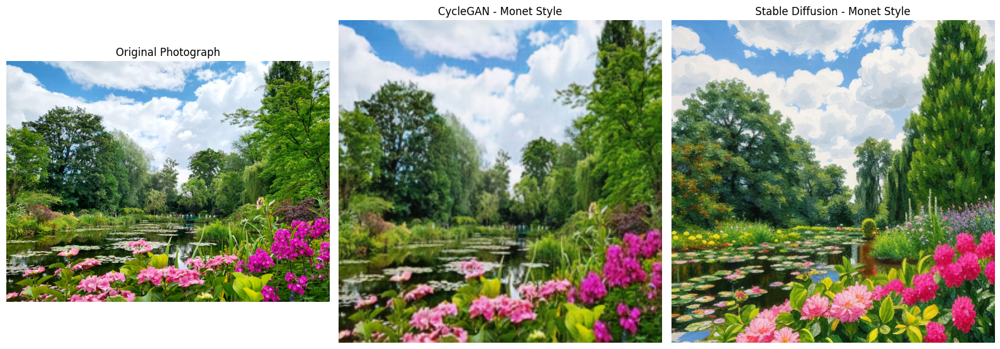

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(16, 6))

plt.subplot(1, 3, 1)
plt.imshow(original_photo)
plt.title("Original Photograph")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(painting)
plt.title("CycleGAN - Monet Style")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(diffusion_result)
plt.title("Stable Diffusion - Monet Style")
plt.axis("off")

plt.tight_layout()
plt.show()

# Install and load BLIP

In [30]:
from transformers import BlipProcessor, BlipForConditionalGeneration
import torch

blip_processor = BlipProcessor.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

blip_model = BlipForConditionalGeneration.from_pretrained(
    "Salesforce/blip-image-captioning-base"
)

blip_model = blip_model.to("cuda")

print("BLIP model loaded successfully!")

preprocessor_config.json:   0%|          | 0.00/287 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.56k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/506 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B /  990MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/473 [00:00<?, ?it/s]

BLIP model loaded successfully!


In [31]:
def generate_caption(image):

    inputs = blip_processor(
        images=image.convert("RGB"),
        return_tensors="pt"
    ).to("cuda")

    with torch.inference_mode():
        output = blip_model.generate(
            **inputs,
            max_new_tokens=50
        )

    caption = blip_processor.decode(
        output[0],
        skip_special_tokens=True
    )

    return caption


print("BLIP caption function created successfully!")

BLIP caption function created successfully!


In [32]:
original_caption = generate_caption(original_photo)

cyclegan_caption = generate_caption(painting)

diffusion_caption = generate_caption(diffusion_result)

print("ORIGINAL IMAGE CAPTION:")
print(original_caption)

print("\nCYCLEGAN IMAGE CAPTION:")
print(cyclegan_caption)

print("\nDIFFUSION IMAGE CAPTION:")
print(diffusion_caption)

ORIGINAL IMAGE CAPTION:
a pond with pink flowers and trees in the background

CYCLEGAN IMAGE CAPTION:
a pond with flowers and trees in the background

DIFFUSION IMAGE CAPTION:
a painting of a garden with water lils and flowers


# U4 – Strength Slider and Gallery Export.

In [33]:
from PIL import Image

def apply_strength(original, generated, strength):

    original = original.convert("RGB")

    generated = generated.convert("RGB")
    generated = generated.resize(original.size)

    result = Image.blend(
        original,
        generated,
        strength
    )

    return result

print("Image strength function created successfully!")

Image strength function created successfully!


In [34]:
import gradio as gr

def change_strength(strength):

    result = apply_strength(
        original_photo,
        painting,
        strength
    )

    return result

demo_slider = gr.Interface(
    fn=change_strength,
    inputs=gr.Slider(
        minimum=0,
        maximum=1,
        value=0.5,
        step=0.05,
        label="Transformation Strength"
    ),
    outputs=gr.Image(type="pil", label="Transformed Image"),
    title="CycleGAN Image Strength Controller",
    description="Adjust the slider to control the blend between original and generated images."
)

demo_slider.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://9f1ca93560e7e7e9e7.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [35]:
import os
import gradio as gr
from PIL import Image

gallery_images = []

def generate_and_save(strength):

    result = apply_strength(
        original_photo,
        painting,
        strength
    )

    os.makedirs("/content/gallery", exist_ok=True)

    filename = f"/content/gallery/image_{len(gallery_images)+1}.png"

    result.save(filename)

    gallery_images.append(filename)

    gallery = [
        Image.open(path).copy()
        for path in gallery_images
    ]

    return gallery, filename


with gr.Blocks() as gallery_demo:

    gr.Markdown("# CycleGAN Image Gallery")

    strength = gr.Slider(
        0, 1, value=0.5,
        label="Transformation Strength"
    )

    generate = gr.Button("Generate Image")

    gallery = gr.Gallery(label="Generated Images")

    download = gr.File(label="Download Image")

    generate.click(
        generate_and_save,
        inputs=strength,
        outputs=[gallery, download]
    )

gallery_demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d36c696c0474226083.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [37]:
import os
import gradio as gr
from PIL import Image

gallery_folder = "/content/gallery"
os.makedirs(gallery_folder, exist_ok=True)

gallery_images = []

def generate_and_save(strength):

    result = apply_strength(
        original_photo,
        painting,
        float(strength)
    )

    filename = os.path.join(
        gallery_folder,
        f"image_{len(gallery_images)+1}.png"
    )

    result.save(filename)

    # Store PIL images for gallery display
    gallery_images.append(result.copy())

    print("Image saved:", filename)

    return gallery_images, filename


with gr.Blocks(title="CycleGAN Image Gallery") as app:

    gr.Markdown("# CycleGAN Image Gallery")

    strength = gr.Slider(
        minimum=0,
        maximum=1,
        value=0.5,
        step=0.05,
        label="Transformation Strength"
    )

    generate = gr.Button("Generate Image")

    gallery = gr.Gallery(
        label="Generated Images",
        columns=3
    )

    download = gr.File(
        label="Download Generated Image"
    )

    generate.click(
        fn=generate_and_save,
        inputs=strength,
        outputs=[gallery, download]
    )

app.launch(
    share=True,
    debug=True,
    allowed_paths=["/content/gallery"]
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d6c95c053fad3ef1be.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Image saved: /content/gallery/image_1.png
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7862 <> https://d6c95c053fad3ef1be.gradio.live


# 5.	U5 — Watermark outputs; add an artist-style copyright note.

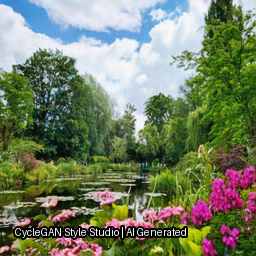

Watermark added successfully!


In [38]:
from PIL import Image, ImageDraw, ImageFont

def add_watermark(image):

    image = image.convert("RGB")

    draw = ImageDraw.Draw(image)

    text = "CycleGAN Style Studio | AI Generated"

    font = ImageFont.load_default()

    position = (15, image.height - 30)

    draw.text(
        position,
        text,
        fill="white",
        font=font,
        stroke_width=2,
        stroke_fill="black"
    )

    return image


watermarked_image = add_watermark(painting)

display(watermarked_image)

print("Watermark added successfully!")

In [39]:
import gradio as gr

copyright_notice = """
### Copyright & Responsible AI Notice

1. Generated images are AI-created transformations.
2. Original image ownership remains with its respective owner.
3. Users must respect copyright and intellectual property rights.
4. Artistic styles are not claimed as copyrighted by this application.
5. Model outputs may contain visual errors or distortions.

**Model:** CycleGAN and Stable Diffusion
**Captioning:** BLIP
**Application:** CycleGAN Style Studio
"""

print(copyright_notice)


### Copyright & Responsible AI Notice

1. Generated images are AI-created transformations.
2. Original image ownership remains with its respective owner.
3. Users must respect copyright and intellectual property rights.
4. Artistic styles are not claimed as copyrighted by this application.
5. Model outputs may contain visual errors or distortions.

**Model:** CycleGAN and Stable Diffusion
**Captioning:** BLIP
**Application:** CycleGAN Style Studio



In [40]:
test_cases = [
    ("Convert horse into zebra", "horse_to_zebra"),
    ("Convert zebra into horse", "zebra_to_horse"),
    ("Make photo look like painting", "photo_to_painting"),
    ("Convert painting into photo", "painting_to_photo"),
    ("Convert building into car", "unsupported")
]

def classify_request(request):

    request = request.lower()

    if "horse" in request and "zebra" in request:
        return "horse_to_zebra" if request.index("horse") < request.index("zebra") else "zebra_to_horse"

    if "zebra" in request and "horse" in request:
        return "zebra_to_horse"

    if "photo" in request and "painting" in request:
        return "photo_to_painting" if request.index("photo") < request.index("painting") else "painting_to_photo"

    return "unsupported"


correct = 0

for request, expected in test_cases:

    predicted = classify_request(request)

    if predicted == expected:
        correct += 1

    print("Request:", request)
    print("Expected:", expected)
    print("Predicted:", predicted)
    print("----------------------")

accuracy = correct / len(test_cases) * 100

print("Test Accuracy:", accuracy, "%")

Request: Convert horse into zebra
Expected: horse_to_zebra
Predicted: horse_to_zebra
----------------------
Request: Convert zebra into horse
Expected: zebra_to_horse
Predicted: zebra_to_horse
----------------------
Request: Make photo look like painting
Expected: photo_to_painting
Predicted: photo_to_painting
----------------------
Request: Convert painting into photo
Expected: painting_to_photo
Predicted: painting_to_photo
----------------------
Request: Convert building into car
Expected: unsupported
Predicted: unsupported
----------------------
Test Accuracy: 100.0 %
